# RDA prompt versions compared

One sample, several saved prompt versions, three models. For every field the person
annotated, each version's output is **Correct** (same value), a **Mismatch** (a
different value) or **Missed** (nothing written there) - the same labels as the field
matrix. Lower mismatch and missed are better; a mismatch is the costlier error, since
it is a wrong value that looks right.

**To compare other versions or another sample:** change `RUNS` and `SAMPLE` in the next cell.


In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if Path.cwd().name == "notebooks":
    import os
    os.chdir(Path.cwd().parent)

from dmpbridge.rda import evaluate as E

SAMPLE = 3
# (label shown in the figure, folder under notebooks/rda-experiments/runs/)
RUNS = [("v9",                "v9-sample3"),
        ("v10",               "v10-sample3"),
        ("v11",               "v11-sample3"),
        ("v12",               "v12-sample3"),
        ("v13",               "v13-sample3")]
MODELS = ["llama3.1-8b", "gemma4-e4b", "llama3.3-70b"]
NAME   = {"llama3.1-8b": "Llama 3.1 8B", "gemma4-e4b": "Gemma 4 e4b", "llama3.3-70b": "Llama 3.3 70B"}
OUTCOMES = ["Correct", "Mismatch", "Missed"]
COLOUR = {"Correct": "#238b45", "Mismatch": "#e34948", "Missed": "#898781"}
OUT_DIR = Path("notebooks/rda-experiments")

INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK,
                     "axes.edgecolor": "#d8d8d4", "legend.frameon": False})
pd.set_option("display.width", 200)


## 1. Score every version


In [2]:
ref = E.reference_path(SAMPLE)
rows = []
for label, run in RUNS:
    for m in MODELS:
        f = Path("notebooks/rda-experiments/runs") / run / f"sample{SAMPLE}.rda.{m}.json"
        if not f.exists():
            print(f"{run}: no {m} output for sample {SAMPLE} - left out")
            continue
        judged, met, outcomes = E.evaluate_file(f, ref)
        c = Counter(outcomes.values())
        rows.append({"version": label.replace("\n", " "), "model": m, "run": run,
                     **{o: c[o] for o in OUTCOMES},
                     "fields written": met["fields output"],
                     "not in reference": sum(r["reason"] == "not in the reference" for r in judged)})
        for field, o in outcomes.items():
            rows[-1].setdefault("_parts", []).append((E.row_of(field)[1], o))

df = pd.DataFrame([{k: v for k, v in r.items() if k != "_parts"} for r in rows])
n_fields = len(outcomes)
versions = [v for v in dict.fromkeys(df["version"])]
print(f"sample {SAMPLE}: {n_fields} annotated fields, {len(versions)} versions, {df['model'].nunique()} models")

totals = (df.groupby("version")[OUTCOMES].sum().reindex(versions))
display(totals)


sample 3: 25 annotated fields, 5 versions, 3 models


,Correct,Mismatch,Missed
version,,,
v9,32,5,38
v10,41,2,32
v11,31,2,42
v12,51,8,16
v13,52,5,18


## 2. The figure: each version, per model and in total

Stacked bars - green correct, red mismatch, grey missed - add up to the annotated
fields (per model) or three times that (total). Saved next to the runs as
`version_comparison_sample{SAMPLE}.png`.


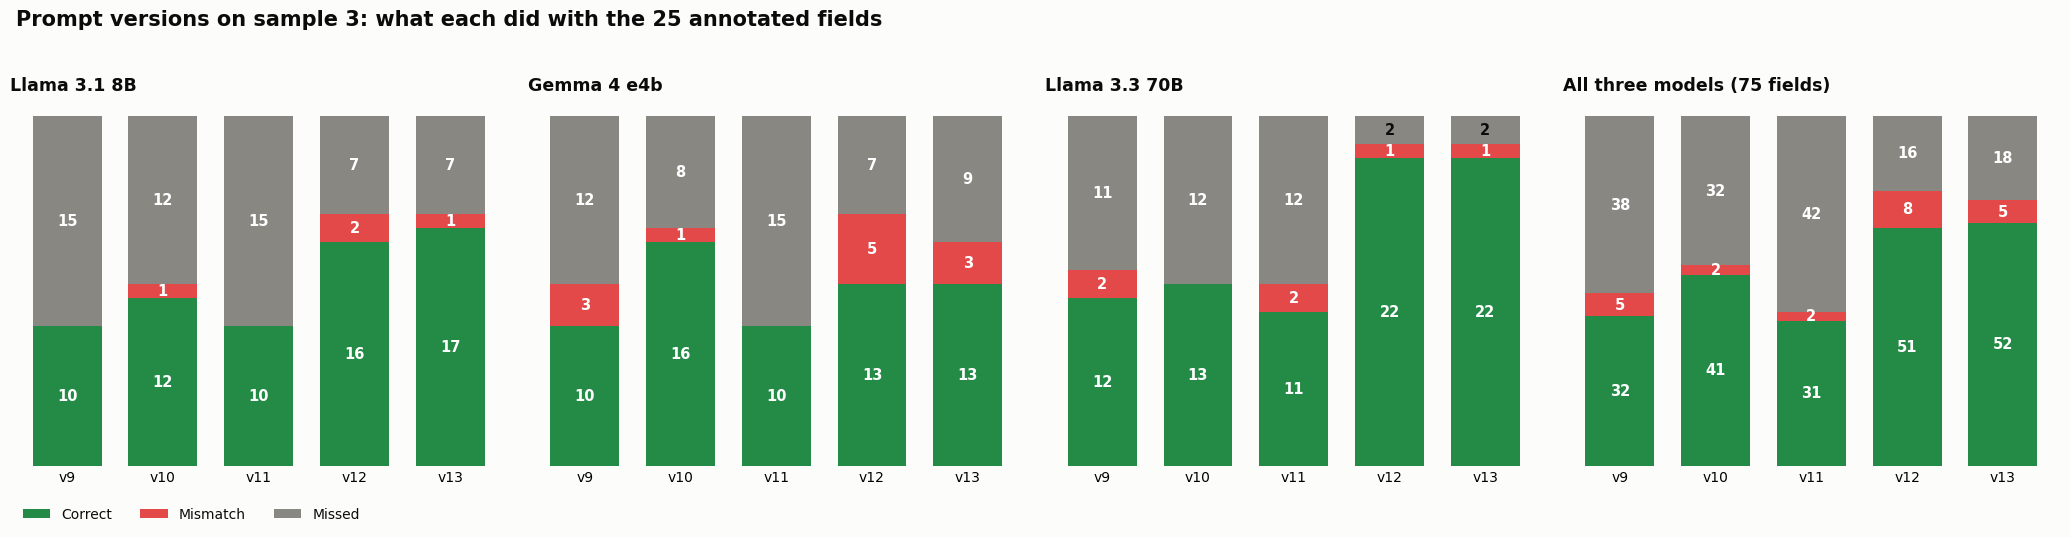

saved -> notebooks\rda-experiments\version_comparison_sample3.png


In [3]:
panels = [(m, df[df["model"] == m].set_index("version").reindex(versions)) for m in MODELS]
panels.append(("total", totals))

fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.6), sharey=False)
for ax, (name, d) in zip(axes, panels):
    bottom = np.zeros(len(d))
    for o in OUTCOMES:
        vals = d[o].fillna(0).to_numpy()
        ax.bar(range(len(d)), vals, bottom=bottom, color=COLOUR[o], width=0.72, label=o)
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v:
                ax.text(i, b + v / 2, f"{int(v)}", ha="center", va="center", fontsize=10.5,
                        color="white" if o != "Missed" or v > 3 else INK, fontweight="bold")
        bottom += vals
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels([l for l, _ in RUNS if l.replace("\n", " ") in d.index], fontsize=10)
    ax.set_title(NAME.get(name, f"All three models ({3 * n_fields} fields)"), fontsize=12.5,
                 fontweight="bold", loc="left")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_yticks([])
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3, fontsize=10)
fig.suptitle(f"Prompt versions on sample {SAMPLE}: what each did with the {n_fields} annotated fields",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
out = OUT_DIR / f"version_comparison_sample{SAMPLE}.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"saved -> {out}")


## 2b. The table as a figure

The same numbers as a picture, for slides or a quick check: per model and in total,
correct / mismatch / missed (tinted like the field matrix - the darker the cell, the
larger its share of the annotated fields), then how many fields the version wrote
that the reference does not have. Saved as
`version_comparison_table_sample{SAMPLE}.png`.


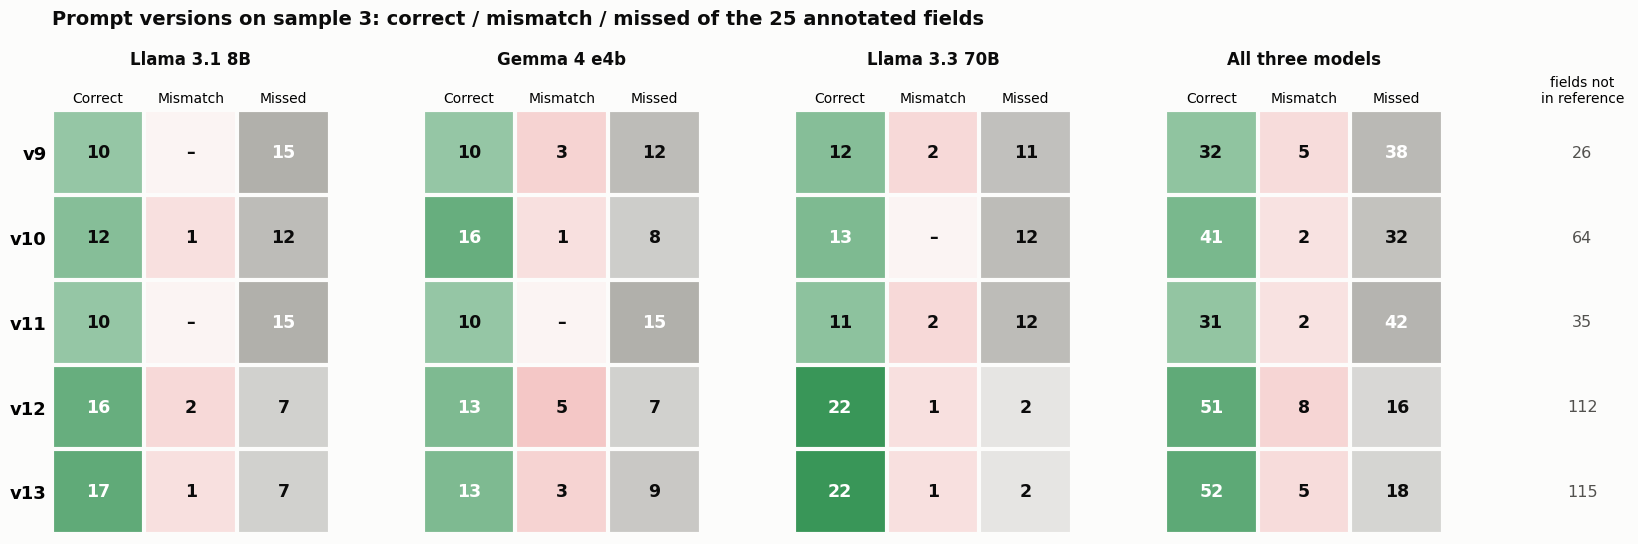

saved -> notebooks\rda-experiments\version_comparison_table_sample3.png


In [4]:
import matplotlib.colors as mcolors

per_model = {m: df[df["model"] == m].set_index("version").reindex(versions) for m in MODELS}
extras = df.groupby("version")["not in reference"].sum().reindex(versions)

groups = [(NAME[m], per_model[m]) for m in MODELS] + [("All three models", totals)]
cols = []                                   # (group, outcome) or (group, None) spacer
for k, (g, _) in enumerate(groups):
    cols += [(g, o) for o in OUTCOMES] + ([(None, None)] if k < len(groups) - 1 else [])
cols += [(None, None), ("", "extras")]
surface = np.array(mcolors.to_rgb(SURFACE))


def cell(v, g, o):
    """(value, share of the annotated fields) for one cell."""
    d = dict(groups)[g]
    n = d.loc[v, o]
    denom = n_fields * (3 if g == "All three models" else 1)
    return int(n), n / denom


img = np.ones((len(versions), len(cols), 3)) * surface
fig, ax = plt.subplots(figsize=(1.05 * len(cols) + 2.5, 0.62 * len(versions) + 2.4))
for i, v in enumerate(versions):
    for j, (g, o) in enumerate(cols):
        if g is None:
            continue
        if o in OUTCOMES:
            n, share = cell(v, g, o)
            strength = 0.12 + 0.88 * share if n else 0.04
            img[i, j] = surface * (1 - strength) + np.array(mcolors.to_rgb(COLOUR[o])) * strength
ax.imshow(img, aspect="auto")
for i, v in enumerate(versions):
    for j, (g, o) in enumerate(cols):
        if g is None:
            continue
        if o in OUTCOMES:
            n, share = cell(v, g, o)
            ax.text(j, i, str(n) if n else "–", ha="center", va="center", fontsize=12.5,
                    fontweight="bold", color="white" if share > 0.5 else INK)
        else:
            ax.text(j, i, f"{int(extras[v])}", ha="center", va="center", fontsize=11.5, color=MUTED)
ax.set_yticks(range(len(versions)))
ax.set_yticklabels(versions, fontsize=13, fontweight="bold")
ax.set_xticks([j for j, (g, o) in enumerate(cols) if g is not None])
ax.set_xticklabels([o if o in OUTCOMES else "fields not\nin reference"
                    for g, o in cols if g is not None], fontsize=10)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for i in range(len(versions) + 1):
    ax.axhline(i - 0.5, color=SURFACE, linewidth=3, zorder=3)
for j in range(len(cols) + 1):
    ax.axvline(j - 0.5, color=SURFACE, linewidth=3, zorder=3)
for g, _ in groups:                         # group names above their three columns
    js = [j for j, (gg, o) in enumerate(cols) if gg == g]
    ax.annotate(g, xy=((js[0] + js[-1]) / 2, 1), xycoords=("data", "axes fraction"), xytext=(0, 30),
                textcoords="offset points", ha="center", va="bottom", fontsize=12, fontweight="bold")
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"Prompt versions on sample {SAMPLE}: correct / mismatch / missed of the {n_fields} annotated fields",
             loc="left", fontsize=14, fontweight="bold", pad=62)
out = OUT_DIR / f"version_comparison_table_sample{SAMPLE}.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"saved -> {out}")


## 2c. The summary table

One row per version: correct / mismatch / missed summed over the three models, each
with its share of the annotated fields, and the prompt size (tokens sent to llama3.1
for this sample, from the run's `run.json`), noting when the schema text is part of
the prompt. Saved as `version_comparison_summary_sample{SAMPLE}.png`.


,Correct ↑,Mismatch ↓,Missed ↓,Prompt size
Version,,,,
v9,32,5,38,"~11,100 tokens (schema text in prompt)"
v10,41,2,32,"~2,300 tokens"
v11,31,2,42,"~2,700 tokens"
v12,51,8,16,"~2,300 tokens"
v13,52,5,18,"~2,300 tokens"


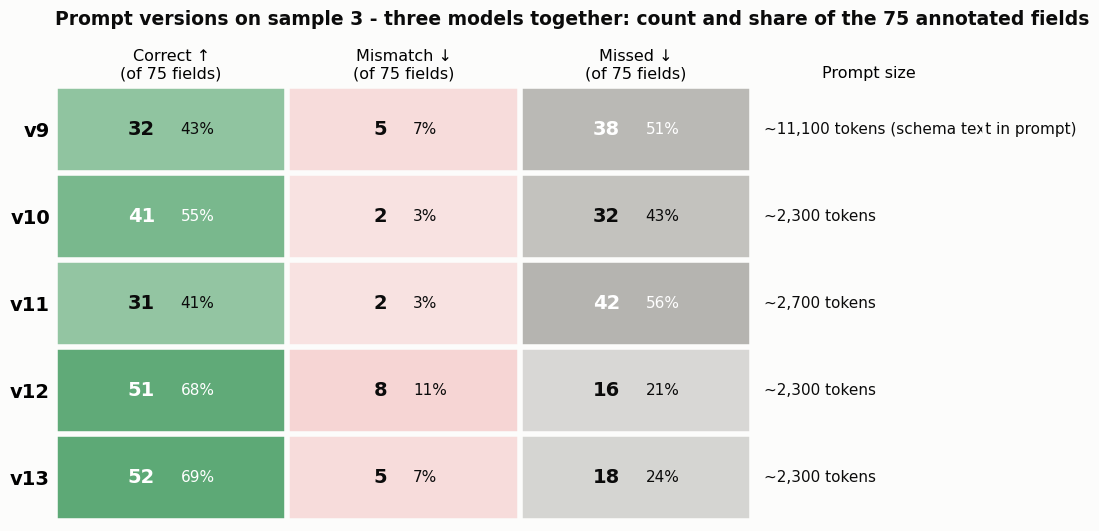

saved -> notebooks\rda-experiments\version_comparison_summary_sample3.png


In [5]:
import json as _json
import matplotlib.colors as mcolors


def prompt_size(run):
    folder = Path("notebooks/rda-experiments/runs") / run
    info = _json.loads((folder / "run.json").read_text(encoding="utf-8"))
    sent = next((t["tokens_sent"] for k, t in info["timings"].items()
                 if k.startswith("llama3.1:8b") and f"sample{SAMPLE}" in k), None)
    prompt = (folder / "prompt.txt").read_text(encoding="utf-8")
    with_schema = "{schema_text}" in prompt or "maDMP JSON schema" in prompt
    size = f"~{round(sent, -2):,} tokens" if sent else "?"
    return size + (" (schema text in prompt)" if with_schema else "")


summary = pd.DataFrame({
    "Version": versions,
    "Correct ↑": totals["Correct"].astype(int).to_numpy(),
    "Mismatch ↓": totals["Mismatch"].astype(int).to_numpy(),
    "Missed ↓": totals["Missed"].astype(int).to_numpy(),
    "Prompt size": [prompt_size(dict((l.replace("\n", " "), r) for l, r in RUNS)[v]) for v in versions],
})
display(summary.set_index("Version"))

# A heatmap: the score cells tinted like the field matrix (darker = larger share of the
# annotated fields), each showing the count and its share; prompt size as text.
score_cols = [("Correct ↑", "Correct"), ("Mismatch ↓", "Mismatch"), ("Missed ↓", "Missed")]
cols = score_cols + [("Prompt size", None)]
n_total = 3 * n_fields
surface = np.array(mcolors.to_rgb(SURFACE))

img = np.ones((len(versions), len(cols), 3)) * surface
for i, v in enumerate(versions):
    for j, (label, outcome) in enumerate(cols):
        if outcome:
            n = int(totals.loc[v, outcome])
            strength = 0.12 + 0.88 * (n / n_total) if n else 0.04
            img[i, j] = surface * (1 - strength) + np.array(mcolors.to_rgb(COLOUR[outcome])) * strength

fig, ax = plt.subplots(figsize=(12, 0.75 * len(versions) + 1.9))
ax.imshow(img, aspect="auto")
for i, v in enumerate(versions):
    for j, (label, outcome) in enumerate(cols):
        if outcome:
            n = int(totals.loc[v, outcome])
            share = n / n_total
            ink = "white" if share > 0.5 else INK
            if n:
                ax.text(j - 0.07, i, str(n), ha="right", va="center", fontsize=14, fontweight="bold", color=ink)
                ax.text(j + 0.04, i, f"{share:.0%}", ha="left", va="center", fontsize=11, color=ink)
            else:
                ax.text(j, i, "–", ha="center", va="center", fontsize=14, color="#c9c8c3")
        else:
            ax.text(j - 0.45, i, summary["Prompt size"][i], ha="left", va="center", fontsize=11, color=INK)
ax.set_yticks(range(len(versions)))
ax.set_yticklabels(versions, fontsize=14, fontweight="bold")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([f"{label}\n(of {n_total} fields)" if outcome else label for label, outcome in cols],
                   fontsize=11.5)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for i in range(len(versions) + 1):
    ax.axhline(i - 0.5, color=SURFACE, linewidth=4, zorder=3)
for j in range(len(cols) + 1):
    ax.axvline(j - 0.5, color=SURFACE, linewidth=4, zorder=3)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"Prompt versions on sample {SAMPLE} - three models together: count and share of the "
             f"{n_total} annotated fields", loc="left", fontsize=13.5, fontweight="bold", pad=44)
out = OUT_DIR / f"version_comparison_summary_sample{SAMPLE}.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"saved -> {out}")


## 2d. Each version, the three models side by side

One panel per version, one stacked bar per model - the same green / red / grey as
above, with the count in each segment and the correct share under the model's name.
Saved as `version_comparison_by_model_sample{SAMPLE}.png`.


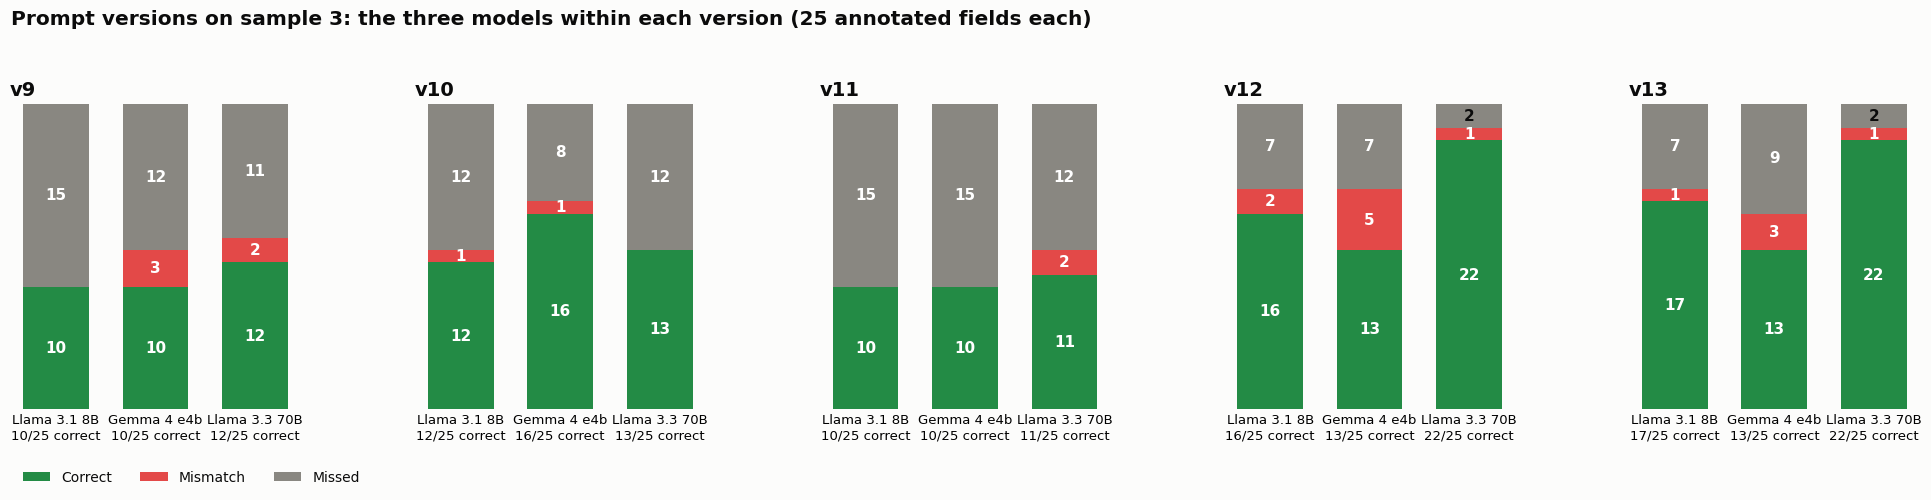

saved -> notebooks\rda-experiments\version_comparison_by_model_sample3.png


In [6]:
fig, axes = plt.subplots(1, len(versions), figsize=(3.9 * len(versions), 5.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, v in zip(axes, versions):
    d = df[df["version"] == v].set_index("model").reindex(MODELS)
    bottom = np.zeros(len(MODELS))
    for o in OUTCOMES:
        vals = d[o].fillna(0).to_numpy()
        ax.bar(range(len(MODELS)), vals, bottom=bottom, color=COLOUR[o], width=0.66, label=o)
        for i, (n, b) in enumerate(zip(vals, bottom)):
            if n:
                ax.text(i, b + n / 2, f"{int(n)}", ha="center", va="center", fontsize=11,
                        fontweight="bold", color="white" if o != "Missed" or n > 3 else INK)
        bottom += vals
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels([f"{NAME[m]}\n{int(d.loc[m, 'Correct'])}/{n_fields} correct" for m in MODELS],
                       fontsize=9.5)
    ax.set_title(v, fontsize=14, fontweight="bold", loc="left")
    ax.set_ylim(0, n_fields)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_yticks([])
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=3, fontsize=10)
fig.suptitle(f"Prompt versions on sample {SAMPLE}: the three models within each version "
             f"({n_fields} annotated fields each)", x=0.01, ha="left", fontsize=14.5, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
out = OUT_DIR / f"version_comparison_by_model_sample{SAMPLE}.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"saved -> {out}")


## 3. Per model

Correct / mismatch / missed for every version and model, then how many fields each
wrote that the reference does not have ("not in reference") - the other kind of wrong
value, which the three labels above do not count.


In [7]:
wide = df.pivot(index="version", columns="model", values=OUTCOMES).reindex(versions)
wide = wide.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)
wide = wide[[(m, c) for m in MODELS for c in OUTCOMES if (m, c) in wide.columns]]
display(wide)
display(df.pivot(index="version", columns="model", values="not in reference").reindex(versions)
          .rename_axis(columns="fields written that the reference does not have"))


model   llama3.1-8b                 gemma4-e4b                 llama3.3-70b                
            Correct Mismatch Missed    Correct Mismatch Missed      Correct Mismatch Missed
version                                                                                    
v9               10        0     15         10        3     12           12        2     11
v10              12        1     12         16        1      8           13        0     12
v11              10        0     15         10        0     15           11        2     12
v12              16        2      7         13        5      7           22        1      2
v13              17        1      7         13        3      9           22        1      2

fields written that the reference does not have,gemma4-e4b,llama3.1-8b,llama3.3-70b
version,,,
v9,9,10,7
v10,25,20,19
v11,14,7,14
v12,29,40,43
v13,22,44,49


## 4. By part of the form, summed over the three models

Which parts of the form each version gets right. Each cell: correct / mismatch / missed
out of the annotated fields in that part (times three models).


In [8]:
parts = Counter(p for r in rows if r["version"] == versions[0] for p, _ in r["_parts"])
order = [p[1] for p in E.ROWS if p[1] in parts]
table = {}
for v in versions:
    c = Counter((p, o) for r in rows if r["version"] == v for p, o in r["_parts"])
    table[v] = [f"{c[(p, 'Correct')]} / {c[(p, 'Mismatch')]} / {c[(p, 'Missed')]}" for p in order]
part_df = pd.DataFrame(table, index=[f"{p}  ({parts[p]})" for p in order])
part_df.index.name = "part of the form (annotated fields x 3 models)"
display(part_df)


,v9,v10,v11,v12,v13
part of the form (annotated fields x 3 models),,,,,
Plan title & description (6),3 / 1 / 2,3 / 0 / 3,3 / 0 / 3,3 / 0 / 3,3 / 0 / 3
Dataset title (12),7 / 2 / 3,10 / 1 / 1,8 / 2 / 2,9 / 1 / 2,9 / 1 / 2
Dataset description (12),4 / 2 / 6,2 / 1 / 9,0 / 0 / 12,8 / 2 / 2,8 / 2 / 2
Personal & sensitive data (24),18 / 0 / 6,22 / 0 / 2,20 / 0 / 4,20 / 0 / 4,20 / 0 / 4
Storage place (host) (3),0 / 0 / 3,1 / 0 / 2,0 / 0 / 3,0 / 3 / 0,0 / 2 / 1
Licence (3),0 / 0 / 3,1 / 0 / 2,0 / 0 / 3,3 / 0 / 0,3 / 0 / 0
Metadata & standards (15),0 / 0 / 15,2 / 0 / 13,0 / 0 / 15,8 / 2 / 5,9 / 0 / 6
